Groupby on DataFrames-->01
--

In [4]:
import numpy as np
import pandas as pd
from pandas import Series,DataFrame

In [6]:
dframe = DataFrame({'k1':['X','X','Y','Y','Z'],
                   'k2':['alpha','beta','alpha','beta','alpha'],
                   'dataset1':np.random.randn(5),
                   'dataset2':np.random.randn(5)})
dframe

,k1,k2,dataset1,dataset2
0,X,alpha,-1.618164,-0.098832
1,X,beta,-1.063096,-1.104638
2,Y,alpha,-0.326384,-0.638105
3,Y,beta,2.037943,-0.592961
4,Z,alpha,-1.222932,0.529675


In [8]:
group1 =dframe['dataset1'].groupby(dframe['k1'])
group1

*we should do some operations to see the result*

In [11]:
group1.mean()

k1
X   -1.340630
Y    0.855780
Z   -1.222932
Name: dataset1, dtype: float64

**group keys**
*ex:we have NY Jan 0.391129 and NY Jan -0.425145. we calculate the mean*

In [14]:
cities = np.array(['NY','LA','LA','NY','NY'])

month = np.array(['JAN','FEB','JAN','FEB','JAN'])

In [16]:
dframe['dataset1'].groupby([cities,month]).mean()

LA  FEB   -1.063096
    JAN   -0.326384
NY  FEB    2.037943
    JAN   -1.420548
Name: dataset1, dtype: float64

In [18]:
dframe

,k1,k2,dataset1,dataset2
0,X,alpha,-1.618164,-0.098832
1,X,beta,-1.063096,-1.104638
2,Y,alpha,-0.326384,-0.638105
3,Y,beta,2.037943,-0.592961
4,Z,alpha,-1.222932,0.529675


**pass column names as groupkey**

In [21]:
dframe.groupby('k1').mean(numeric_only=True)

,dataset1,dataset2
k1,,
X,-1.340630,-0.601735
Y,0.855780,-0.615533
Z,-1.222932,0.529675


In [23]:
dframe.groupby(['k1','k2']).mean()

dataset1  dataset2
k1 k2                       
X  alpha -1.618164 -0.098832
   beta  -1.063096 -1.104638
Y  alpha -0.326384 -0.638105
   beta   2.037943 -0.592961
Z  alpha -1.222932  0.529675

**size**

In [26]:
dframe.groupby(['k1']).size()

k1
X    2
Y    2
Z    1
dtype: int64

**iterate over groups**

In [29]:
for name,group in dframe.groupby('k1'):
    print('This is the %s group'%name)
    print(group)
    print('/n')

This is the X group
  k1     k2  dataset1  dataset2
0  X  alpha -1.618164 -0.098832
1  X   beta -1.063096 -1.104638
/n
This is the Y group
  k1     k2  dataset1  dataset2
2  Y  alpha -0.326384 -0.638105
3  Y   beta  2.037943 -0.592961
/n
This is the Z group
  k1     k2  dataset1  dataset2
4  Z  alpha -1.222932  0.529675
/n


In [31]:
for (k1,k2),group in dframe.groupby(['k1','k2']):
    print("key1 = %s key2 = %s" %(k1,k2))
    print(group)
    print('\n')
    

key1 = X key2 = alpha
  k1     k2  dataset1  dataset2
0  X  alpha -1.618164 -0.098832


key1 = X key2 = beta
  k1    k2  dataset1  dataset2
1  X  beta -1.063096 -1.104638


key1 = Y key2 = alpha
  k1     k2  dataset1  dataset2
2  Y  alpha -0.326384 -0.638105


key1 = Y key2 = beta
  k1    k2  dataset1  dataset2
3  Y  beta  2.037943 -0.592961


key1 = Z key2 = alpha
  k1     k2  dataset1  dataset2
4  Z  alpha -1.222932  0.529675




**dictionaries**

In [34]:
# my_dic = dict(m = 'forouzan',b='mv')
# my_dic
list(dframe.groupby('k1'))

[('X',
    k1     k2  dataset1  dataset2
  0  X  alpha -1.618164 -0.098832
  1  X   beta -1.063096 -1.104638),
 ('Y',
    k1     k2  dataset1  dataset2
  2  Y  alpha -0.326384 -0.638105
  3  Y   beta  2.037943 -0.592961),
 ('Z',
    k1     k2  dataset1  dataset2
  4  Z  alpha -1.222932  0.529675)]

In [36]:
group_dict = dict(list(dframe.groupby('k1')))

In [38]:
group_dict

{'X':   k1     k2  dataset1  dataset2
 0  X  alpha -1.618164 -0.098832
 1  X   beta -1.063096 -1.104638,
 'Y':   k1     k2  dataset1  dataset2
 2  Y  alpha -0.326384 -0.638105
 3  Y   beta  2.037943 -0.592961,
 'Z':   k1     k2  dataset1  dataset2
 4  Z  alpha -1.222932  0.529675}

In [40]:
group_dict['X']

,k1,k2,dataset1,dataset2
0,X,alpha,-1.618164,-0.098832
1,X,beta,-1.063096,-1.104638


**group by datatypes**

In [43]:
dframe

,k1,k2,dataset1,dataset2
0,X,alpha,-1.618164,-0.098832
1,X,beta,-1.063096,-1.104638
2,Y,alpha,-0.326384,-0.638105
3,Y,beta,2.037943,-0.592961
4,Z,alpha,-1.222932,0.529675


In [45]:
# dframe.loc[rows,columns]
dframe.loc[:,'k2']

0    alpha
1     beta
2    alpha
3     beta
4    alpha
Name: k2, dtype: object

In [47]:
# dframe.dtypes == dtype: take columns that has the same datatype.
# axis = 0 --> rows
# axis = 1 --> columns


# 1
# group_dict_axis1 = {}
# for dtype in dframe.dtypes.unique():
#     group_dict_axis1[dtype] = dframe.loc[:, dframe.dtypes == dtype]


# 2
# dic comprehension
group_dict_axis1 = {
    dtype:dframe.loc[:,dframe.dtypes==dtype] 
    for dtype in dframe.dtypes.unique()
}
group_dict_axis1


{dtype('O'):   k1     k2
 0  X  alpha
 1  X   beta
 2  Y  alpha
 3  Y   beta
 4  Z  alpha,
 dtype('float64'):    dataset1  dataset2
 0 -1.618164 -0.098832
 1 -1.063096 -1.104638
 2 -0.326384 -0.638105
 3  2.037943 -0.592961
 4 -1.222932  0.529675}

**use groupby with columns**
dataset in 2 columns with both set of keys

In [50]:
# mean of dataset2 with both keys
dataset2_group = dframe.groupby(['k1','k2'])[['dataset2']]
dataset2_group.mean()

dataset2
k1 k2             
X  alpha -0.098832
   beta  -1.104638
Y  alpha -0.638105
   beta  -0.592961
Z  alpha  0.529675

Groupby on Dict,Series-->02
--

In [53]:
import numpy as np
import pandas as pd
from pandas import Series, DataFrame

In [55]:
animals = DataFrame(np.arange(16).reshape(4,4),
                   columns=['W','X','Y','Z'],
                   index=['Dog','Cat','Bird','Mouse'])
animals

,W,X,Y,Z
Dog,0,1,2,3
Cat,4,5,6,7
Bird,8,9,10,11
Mouse,12,13,14,15


In [57]:
# iloc → position / number
# loc  → label / name
animals.loc['Cat',['W','Y']] = np.nan

In [59]:
animals

,W,X,Y,Z
Dog,0.0,1,2.0,3
Cat,NaN,5,NaN,7
Bird,8.0,9,10.0,11
Mouse,12.0,13,14.0,15


**dict**

In [62]:
behavior_map = {'W':'good','X':'bad','Y':'good','Z':'bad'}

In [64]:
animal_col = animals.T.groupby(behavior_map).sum().T
animal_col

,bad,good
Dog,4.0,2.0
Cat,12.0,0.0
Bird,20.0,18.0
Mouse,28.0,26.0


**Series**

In [67]:
behav_series = Series(behavior_map)
behav_series

W    good
X     bad
Y    good
Z     bad
dtype: object

In [69]:
animals.T.groupby(behav_series).count().T

,bad,good
Dog,2,2
Cat,2,0
Bird,2,2
Mouse,2,2


In [71]:
animals

,W,X,Y,Z
Dog,0.0,1,2.0,3
Cat,NaN,5,NaN,7
Bird,8.0,9,10.0,11
Mouse,12.0,13,14.0,15


**group by length of animals name**

In [74]:
animals.groupby(len).sum()

,W,X,Y,Z
3,0.0,6,2.0,10
4,8.0,9,10.0,11
5,12.0,13,14.0,15


**make functions with array,dic,series for groupby mehtods**

In [77]:
keys = ['A','A','A','B']

In [79]:
animals.groupby([len,keys]).max()
# groupby().max() finds the maximum value in each column within each group

,,W,X,Y,Z
3,A,0.0,5,2.0,7
4,A,8.0,9,10.0,11
5,B,12.0,13,14.0,15


**groupby with index hierarchy level😬**

In [82]:
# MultiIndex.from_arrays() creates a MultiIndex from multiple arrays, where each array represents one level of the index.
hier_col = pd.MultiIndex.from_arrays([['NY','NY','NY','SF','SF' ],[1,2,3,1,2]],names=['City','sub_value'])

In [84]:
hier_col

MultiIndex([('NY', 1),
            ('NY', 2),
            ('NY', 3),
            ('SF', 1),
            ('SF', 2)],
           names=['City', 'sub_value'])

In [86]:
dframe_hr = DataFrame(np.arange(25).reshape(5,5),columns=hier_col)
dframe_hr = dframe_hr * 100
dframe_hr

City         NY                SF      
sub_value     1     2     3     1     2
0             0   100   200   300   400
1           500   600   700   800   900
2          1000  1100  1200  1300  1400
3          1500  1600  1700  1800  1900
4          2000  2100  2200  2300  2400

In [88]:
dframe_hr.T.groupby(level='City').sum().T

City,NY,SF
0,300,700
1,1800,1700
2,3300,2700
3,4800,3700
4,6300,4700


Data Aggregation -->03
--
It is consists of operations with scalar result like sum,min,max,count...

In [91]:
import numpy as np
import pandas as pd 
from pandas import Series, DataFrame

https://archive.ics.uci.edu/dataset/186/wine+quality

**Read csv file**

In [95]:
# they seperated with commas
dframe_wine = pd.read_csv('winequality-red.csv',sep=';')
dframe_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


**average alcohol content**

In [98]:
dframe_wine['alcohol'].mean()

10.422983114446529

**make our own Data Aggregation**

In [101]:
def max_to_min(arr):
    return arr.max() - arr.min()

In [103]:
wino = dframe_wine.groupby('quality')

In [105]:
wino.describe()

fixed acidity                                                     \
                count      mean       std  min   25%   50%     75%   max   
quality                                                                    
3                10.0  8.360000  1.770875  6.7  7.15  7.50   9.875  11.6   
4                53.0  7.779245  1.626624  4.6  6.80  7.50   8.400  12.5   
5               681.0  8.167254  1.563988  5.0  7.10  7.80   8.900  15.9   
6               638.0  8.347179  1.797849  4.7  7.00  7.90   9.400  14.3   
7               199.0  8.872362  1.992483  4.9  7.40  8.80  10.100  15.6   
8                18.0  8.566667  2.119656  5.0  7.25  8.25  10.225  12.6   

        volatile acidity            ... sulphates       alcohol             \
                   count      mean  ...       75%   max   count       mean   
quality                             ...                                      
3                   10.0  0.884500  ...     0.615  0.86    10.0   9.955000   
4                   53.0  0.693962  ...     0.600  2.00    53.0  10.265094   
5                  681.0  0.577041  ...     0.660  1.98   681.0   9.899706   
6                  638.0  0.497484  ...     0.750  1.95   638.0  10.629519   
7                  199.0  0.403920  ...     0.830  1.36   199.0  11.465913   
8                   18.0  0.423333  ...     0.820  1.10    18.0  12.094444   

                                                      
              std  min     25%     50%     75%   max  
quality                                               
3        0.818009  8.4   9.725   9.925  10.575  11.0  
4        0.934776  9.0   9.600  10.000  11.000  13.1  
5        0.736521  8.5   9.400   9.700  10.200  14.9  
6        1.049639  8.4   9.800  10.500  11.300  14.0  
7        0.961933  9.2  10.800  11.500  12.100  14.0  
8        1.224011  9.8  11.325  12.150  12.875  14.0  

[6 rows x 88 columns]

In [107]:
wino.agg(max_to_min)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,4.9,1.140,0.66,4.5,0.206,31.0,40.0,0.00609,0.47,0.46,2.6
4,7.9,0.900,1.00,11.6,0.565,38.0,112.0,0.00760,1.16,1.67,4.1
5,10.9,1.150,0.79,14.3,0.572,65.0,149.0,0.01059,0.86,1.61,6.4
6,9.6,0.880,0.78,14.5,0.381,71.0,159.0,0.01362,1.15,1.55,5.6
7,10.7,0.795,0.76,7.7,0.346,51.0,282.0,0.01256,0.86,0.97,4.8
8,7.6,0.590,0.69,5.0,0.042,39.0,76.0,0.00800,0.84,0.47,4.2


In [109]:
wino.agg('mean')

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,8.360000,0.884500,0.171000,2.635000,0.122500,11.000000,24.900000,0.997464,3.398000,0.570000,9.955000
4,7.779245,0.693962,0.174151,2.694340,0.090679,12.264151,36.245283,0.996542,3.381509,0.596415,10.265094
5,8.167254,0.577041,0.243686,2.528855,0.092736,16.983847,56.513950,0.997104,3.304949,0.620969,9.899706
6,8.347179,0.497484,0.273824,2.477194,0.084956,15.711599,40.869906,0.996615,3.318072,0.675329,10.629519
7,8.872362,0.403920,0.375176,2.720603,0.076588,14.045226,35.020101,0.996104,3.290754,0.741256,11.465913
8,8.566667,0.423333,0.391111,2.577778,0.068444,13.277778,33.444444,0.995212,3.267222,0.767778,12.094444


In [111]:
dframe_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


**add quality to alcohol content ratio**
*if quality rating has a link to the alcohal percentage of the wine*

**افزودن نسبت کیفیت به میزان الکل**
*اگر رتبه‌بندی کیفیت با درصد الکل شراب مرتبط باشد*

In [120]:
dframe_wine['qual/alc ratio'] = dframe_wine['quality']/dframe_wine['alcohol']

In [126]:
dframe_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,qual/alc ratio
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0.531915
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0.510204
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0.510204
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0.612245
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0.531915


**pivot tables instead of groupby**

In [ ]:
dframe_wine.pivot_table(index=['quality'])

**Data visualization**

<Axes: xlabel='quality', ylabel='alcohol'>

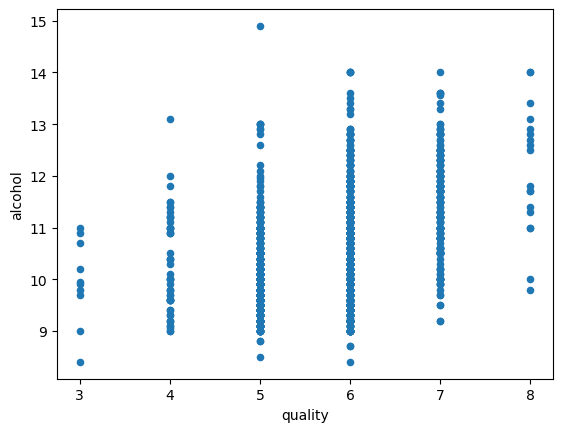

In [134]:
dframe_wine.plot(kind='scatter',x='quality',y='alcohol')

split,apply,combine -->04
--

In [244]:
import numpy as np
import pandas as pd
from pandas import Series, DataFrame

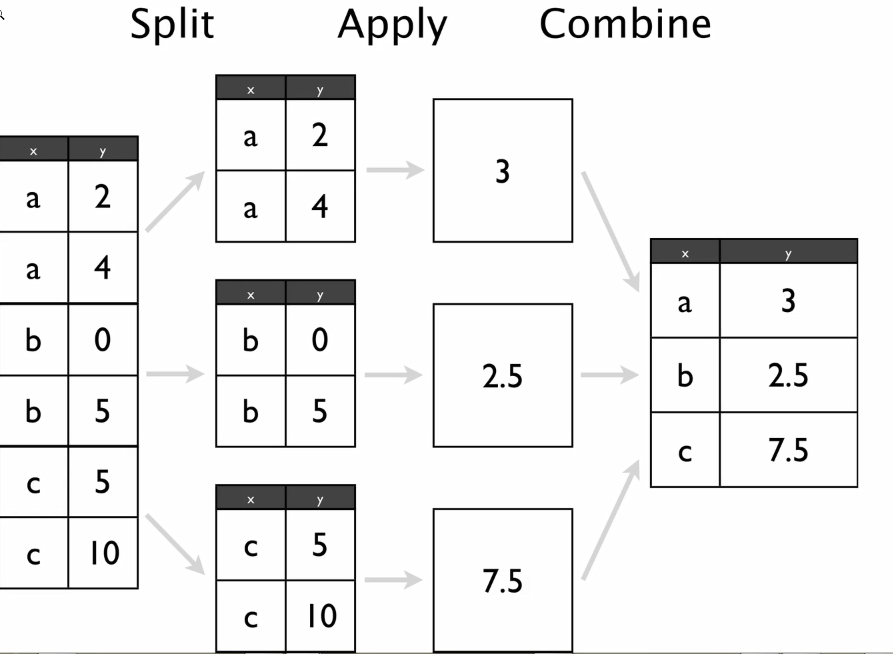

In [246]:
from IPython.display import Image
Image("C:\\Users\\ALFA\\Pictures\\Screenshots\\Screenshot (412).png")

In [248]:
dframe_wine = pd.read_csv('winequality-red.csv',sep=';')
dframe_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


**highest alcohal content for each quality range**
**بیشترین میزان الکل برای هر رده کیفی**

**function that assign rank to each wine**

In [252]:
def ranker(df):  
    df['alc_content_rank'] = np.arange(len(df))+1
    return df

In [254]:
# dframe_wine['f']=np.arange(len(dframe_wine))+1
# # dframe_wine

**sort dataframe by alcohal in ascending order**

sort_values → مرتب‌سازی بر اساس مقدار ستون

ascending=False → از بزرگ به کوچک

In [257]:
dframe_wine.sort_values('alcohol',ascending=False,inplace=True)

In [259]:
dframe_wine = dframe_wine.groupby('quality').apply(
    ranker,
    include_groups=False
)
# execute ranker on each group
# include_groups=False
# Group by quality, but don't include the quality column when running ranker.

In [267]:
dframe_wine.head()

fixed acidity  volatile acidity  citric acid  residual sugar  \
quality                                                                      
3       899             8.3             1.020         0.02            3.40   
        1299            7.6             1.580         0.00            2.10   
        690             7.4             1.185         0.00            4.25   
        1478            7.1             0.875         0.05            5.70   
        1505            6.7             0.760         0.02            1.80   

              chlorides  free sulfur dioxide  total sulfur dioxide  density  \
quality                                                                       
3       899       0.084                  6.0                  11.0  0.99892   
        1299      0.137                  5.0                   9.0  0.99476   
        690       0.097                  5.0                  14.0  0.99660   
        1478      0.082                  3.0                  14.0  0.99808   
        1505      0.078                  6.0                  12.0  0.99600   

                pH  sulphates  alcohol  alc_content_rank  
quality                                                   
3       899   3.48       0.49    11.00                 1  
        1299  3.50       0.40    10.90                 2  
        690   3.63       0.54    10.70                 3  
        1478  3.40       0.52    10.20                 4  
        1505  3.55       0.63     9.95                 5

**call dataframe where alcohol content rank equals =1**

In [276]:
# ❌
num_of_qual = dframe_wine[dframe_wine['alc_content_rank'] == 1]

,quality,level_1,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,alc_content_rank
0,3,899,8.3,1.02,0.02,3.4,0.084,6.0,11.0,0.99892,3.48,0.49,11.0,1
10,4,45,4.6,0.52,0.15,2.1,0.054,8.0,65.0,0.99340,3.90,0.56,13.1,1
63,5,652,15.9,0.36,0.65,7.5,0.096,22.0,71.0,0.99760,2.98,0.84,14.9,1
744,6,142,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,1
1382,7,821,4.9,0.42,0.00,2.1,0.048,16.0,42.0,0.99154,3.71,0.74,14.0,1
1581,8,588,5.0,0.42,0.24,2.0,0.060,19.0,50.0,0.99170,3.72,0.74,14.0,1


**combine info for hieghest alcohal**

In [281]:
dframe_wine[dframe_wine.alc_content_rank == 1]

,quality,level_1,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,alc_content_rank
0,3,899,8.3,1.02,0.02,3.4,0.084,6.0,11.0,0.99892,3.48,0.49,11.0,1
10,4,45,4.6,0.52,0.15,2.1,0.054,8.0,65.0,0.99340,3.90,0.56,13.1,1
63,5,652,15.9,0.36,0.65,7.5,0.096,22.0,71.0,0.99760,2.98,0.84,14.9,1
744,6,142,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,1
1382,7,821,4.9,0.42,0.00,2.1,0.048,16.0,42.0,0.99154,3.71,0.74,14.0,1
1581,8,588,5.0,0.42,0.24,2.0,0.060,19.0,50.0,0.99170,3.72,0.74,14.0,1


Cross Tabulation-->05
--

In [284]:
import pandas as pd

**dataset**
*StringIO lets you treat a string like a file.*

In [290]:
from io import StringIO

In [307]:
data = """\
Sample Animal Intelligence
1 Dog Smart
2 Dog Smart
3 Cat Dumb
4 Cat Dumb
5 Dog Dumb
6 Cat Smart
"""

In [309]:
dframe = pd.read_table(StringIO(data),sep=' ')
dframe

,Sample,Animal,Intelligence
0,1,Dog,Smart
1,2,Dog,Smart
2,3,Cat,Dumb
3,4,Cat,Dumb
4,5,Dog,Dumb
5,6,Cat,Smart


**cross Tabulation Table**
it counts the total number of cats,dogs and all

In [312]:
pd.crosstab(dframe.Animal,dframe.Intelligence,margins=True)

Intelligence,Dumb,Smart,All
Animal,,,
Cat,2,1,3
Dog,1,2,3
All,3,3,6
